# **Prepared by Oh Yu Qiao (24013567)**

# Graded Open-Ended Lab

## Sequential Data Prediction in Engineering Using Autoregressive (AR) Models and Long Short-Term Memory (LSTM) Networks

**Objective**
This lab explores the application of sequential data prediction in engineering contexts evaluating the performance of both traditional Autoregressive (AR) models and modern Long Short-Term Memory (LSTM) neural networks.

The following section shows the code sample to implement an AR model and an LSTM model.

### Code Sample for AR and LSTM models

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

The following code block generate a time series data using the sine function and a normally distributed white noise.

In [ ]:
# Example: Creating a sine wave with noise as the time series data
np.random.seed(42)
time = np.arange(0, 100, 0.1)
data_values = np.sin(time) + np.random.normal(scale=0.5, size=len(time))

# Convert to pandas DataFrame
df = pd.DataFrame({'time': time, 'value': data_values})

# Plot the data
plt.figure(figsize=(10,6))
plt.plot(df['time'], df['value'], label='Original Data')
plt.title('Time Series Data')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

# Split the data into train and test sets
train_size = int(len(df) * 0.8)
train_data = df['value'][:train_size]
test_data = df['value'][train_size:]

### Exploratory Visualizations: ACF and PACF for AR Lag Selection
Before fitting an Autoregressive model, plotting the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) helps students analytically determine the optimal lag order instead of guessing.

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train_data, ax=axes[0], lags=30)
axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(train_data, ax=axes[1], lags=30, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import root_mean_squared_error

The following code block shows the training and evaluation of a autoregressive (AR) model with lags of 5.

In [ ]:
# Fit the Autoregressive (AR) model
model_ar = AutoReg(train_data, lags=5)  # Using lag=5 as an example
model_fit = model_ar.fit()

# Print summary of the model
print(model_fit.summary())

# Make predictions
predictions_ar = model_fit.predict(start=len(train_data), end=len(df)-1, dynamic=False)

# Evaluate the model
rmse = root_mean_squared_error(test_data, predictions_ar)
print(f'RMSE of the AR Model: {rmse}')

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_squared_error

The following code block shows the data preprocessing prior to LSTM model training specifically:
1. min-max scaling
2. converting the sequential data into chunks of 10
3. splitting the data into training and testing data with 80:20 ratio
4. reshaping the training and testing data to be compatible with LSTM

In [ ]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['value'].values.reshape(-1,1))

# Create sequences for LSTM
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

sequence_length = 10
X, y = create_sequences(scaled_data, sequence_length)

# Split the data into training and testing sets
train_size_lstm = int(len(X) * 0.8)
X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y[:train_size_lstm], y[train_size_lstm:]

# Reshape the data to be compatible with LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

The following code block shows the construction and training of an LSTM network with 50 units of hidden neurons.

In [ ]:
# Build the LSTM model
model = Sequential()
model.add(LSTM(50, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))  # Output layer
model.compile(optimizer='adam', loss='mse')

# Train the LSTM model
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test), verbose=0)

# Make predictions
predicted_test = model.predict(X_test)
predicted_test = scaler.inverse_transform(predicted_test)
y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1, 1))

# Evaluate the model
rmse_lstm = root_mean_squared_error(y_test_rescaled, predicted_test)
print(f'RMSE of the LSTM Model: {rmse_lstm}')

### Advanced Comparative Visualizations
To better evaluate micro-level tracking, phase lags, and error distribution between AR and LSTM models, run the visualization cells below.

In [ ]:
# 1. Zoomed-In Comparison Window (First 100 test steps)
zoom_steps = 100
test_time_axis = df['time'][train_size + sequence_length : train_size + sequence_length + zoom_steps]

plt.figure(figsize=(12, 5))
plt.plot(test_time_axis, y_test_rescaled[:zoom_steps], label='Actual Data', color='black', linewidth=2)
plt.plot(test_time_axis, predictions_ar.iloc[:zoom_steps], label='AR Predictions', color='blue', linestyle='--')
plt.plot(test_time_axis, predicted_test[:zoom_steps], label='LSTM Predictions', color='red')
plt.title('Zoomed-In Model Comparison (Phase Lag & Tracking Analysis)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 2. Residual Error Distribution
ar_residuals = test_data.values[:len(predicted_test)] - predictions_ar.values[:len(predicted_test)]
lstm_residuals = y_test_rescaled.flatten() - predicted_test.flatten()

plt.figure(figsize=(10, 5))
plt.hist(ar_residuals, bins=30, alpha=0.5, label='AR Residuals', color='blue')
plt.hist(lstm_residuals, bins=30, alpha=0.5, label='LSTM Residuals', color='red')
plt.title('Error Residual Distribution Histogram')
plt.xlabel('Prediction Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

## Instructions

Download the training and testing data by running the following code block. You can view the downloaded files by clicking on "Files" on the vertical toolbar on the left side of this Jupyter notebook.

The original dataset is provided by https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data.

In [1]:
!gdown 17kLwUsh0N_bBwmbrvcbOC8L_8I49CyvX
!gdown 18jUJjBe3y3hHxexZfTWORaePrxu7qsAM

Downloading...
From: https://drive.google.com/uc?id=17kLwUsh0N_bBwmbrvcbOC8L_8I49CyvX
To: /content/DailyDelhiClimateTrain.csv
100% 78.2k/78.2k [00:00<00:00, 14.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=18jUJjBe3y3hHxexZfTWORaePrxu7qsAM
To: /content/DailyDelhiClimateTest.csv
100% 7.10k/7.10k [00:00<00:00, 15.2MB/s]


In [2]:
!ls -lh *.csv

-rw-r--r-- 1 root root 7.0K Oct 16  2024 DailyDelhiClimateTest.csv
-rw-r--r-- 1 root root  77K Oct 16  2024 DailyDelhiClimateTrain.csv


---
# Lab Report: AR vs LSTM for Daily Temperature Prediction
**Name:** Oh Yu Qiao | **Student ID:** 24013567

## Abstract
*(Write this last: 3–4 lines summarising what you did and the main result.)*

## 1. Setup

In [4]:
# Libraries Imports
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (root_mean_squared_error,
                             mean_absolute_error,
                             mean_absolute_percentage_error)

# Reproducibility: fix all random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Plot style
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True


TensorFlow version: 2.21.0


All the libraries required are imported in one place. Furthermore, the random seeds for Python, NumPy and TensorFlow are also fixed with the value of 42, so that the results, especially LSTM training are reproducible when we rerun the notebook.

## 2. Data Loading and Cleaning
The dataset used is the Daily Delhi Climate dataset from Kaggle. Each row is one day with four variables: mean temperature (°C), humidity (%), wind speed (km/h) and mean pressure (hPa). The target variable for this study is **meantemp** (daily mean temperature).

In [6]:
# Load train and test files
train_df = pd.read_csv('DailyDelhiClimateTrain.csv', parse_dates=['date'], index_col='date')
test_df  = pd.read_csv('DailyDelhiClimateTest.csv',  parse_dates=['date'], index_col='date')

train_df = train_df.sort_index()
test_df  = test_df.sort_index()

# Display information regarding the data
print(f"Train: {train_df.shape[0]} rows, {train_df.index.min().date()} to {train_df.index.max().date()}")
print(f"Test : {test_df.shape[0]} rows, {test_df.index.min().date()} to {test_df.index.max().date()}")
display(train_df.head())

Train: 1462 rows, 2013-01-01 to 2017-01-01
Test : 114 rows, 2017-01-01 to 2017-04-24


,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [7]:
# Checking for Inconsistency, gaps, missing data in the database

# 1. Missing values
print("Missing values (train):\n", train_df.isna().sum(), "\n")
print("Missing values (test):\n",  test_df.isna().sum(), "\n")

# 2. Duplicate dates
print("Duplicate dates in train:", train_df.index.duplicated().sum())
print("Duplicate dates in test :", test_df.index.duplicated().sum())

# 3. Overlap between train and test
overlap = train_df.index.intersection(test_df.index)
print("Dates appearing in BOTH train and test:", list(overlap.date))

# 4. Gaps: is every day present?
for name, d in [('train', train_df), ('test', test_df)]:
    full_range = pd.date_range(d.index.min(), d.index.max(), freq='D')
    print(f"Missing days in {name}: {len(full_range.difference(d.index))}")

# 5. Summary statistics (look for impossible values)
display(train_df.describe().round(2))
display(test_df.describe().round(2))

Missing values (train):
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64 

Missing values (test):
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64 

Duplicate dates in train: 0
Duplicate dates in test : 0
Dates appearing in BOTH train and test: [datetime.date(2017, 1, 1)]
Missing days in train: 0
Missing days in test: 0


,meantemp,humidity,wind_speed,meanpressure
count,1462.00,1462.00,1462.00,1462.00
mean,25.50,60.77,6.80,1011.10
std,7.35,16.77,4.56,180.23
min,6.00,13.43,0.00,-3.04
25%,18.86,50.38,3.48,1001.58
50%,27.71,62.62,6.22,1008.56
75%,31.31,72.22,9.24,1014.94
max,38.71,100.00,42.22,7679.33


,meantemp,humidity,wind_speed,meanpressure
count,114.00,114.00,114.00,114.00
mean,21.71,56.26,8.14,1004.04
std,6.36,19.07,3.59,89.47
min,11.00,17.75,1.39,59.00
25%,16.44,39.62,5.56,1007.44
50%,19.88,57.75,8.07,1012.74
75%,27.71,71.90,10.07,1016.74
max,34.50,95.83,19.31,1022.81


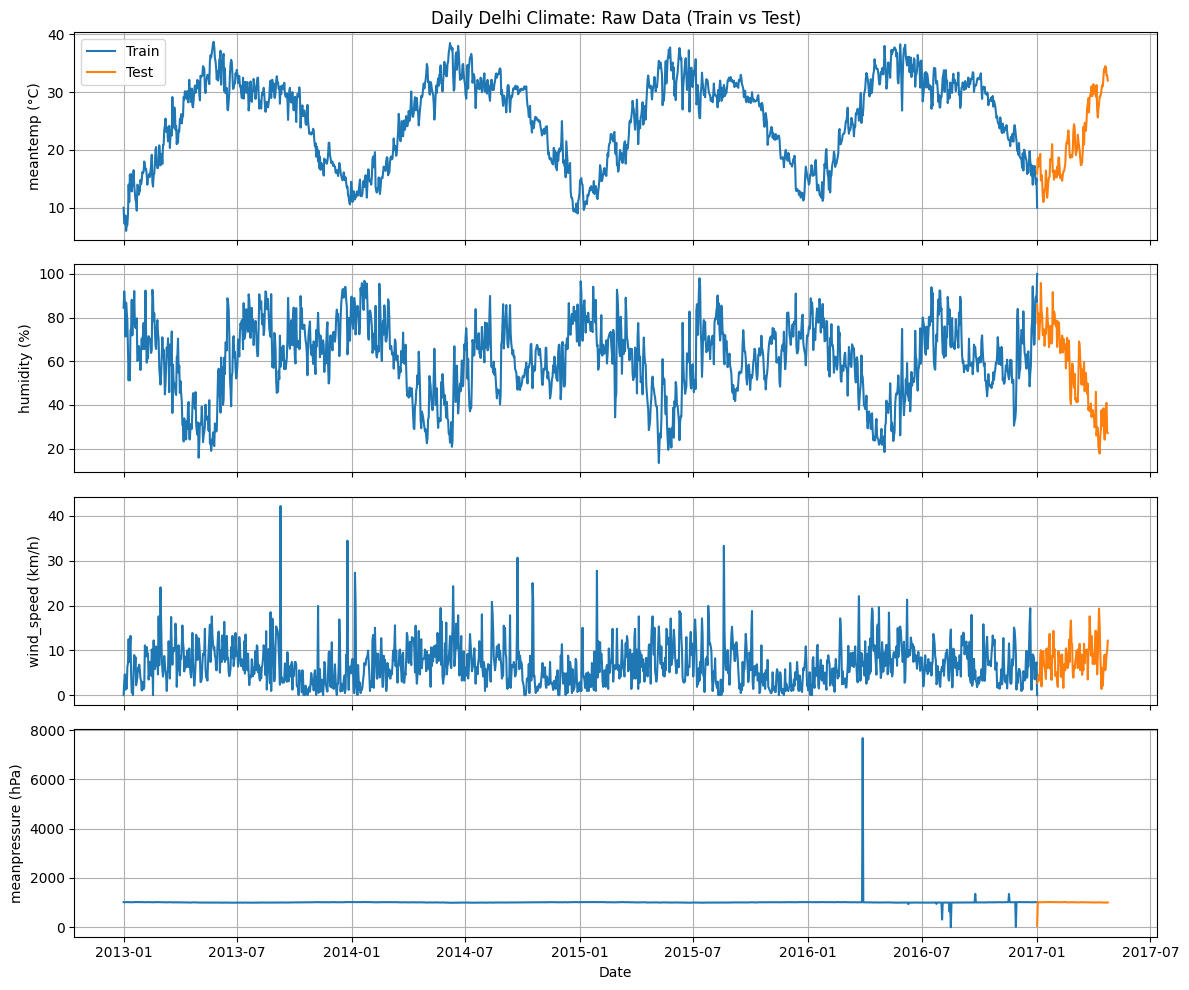

In [8]:
# Quick visual check for all four variables to make sure that they are consistent and the split is good
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, col, unit in zip(axes,
                         ['meantemp', 'humidity', 'wind_speed', 'meanpressure'],
                         ['°C', '%', 'km/h', 'hPa']):
    ax.plot(train_df.index, train_df[col], label='Train', color='tab:blue')
    ax.plot(test_df.index,  test_df[col],  label='Test',  color='tab:orange')
    ax.set_ylabel(f'{col} ({unit})')
axes[0].legend()
axes[0].set_title('Daily Delhi Climate: Raw Data (Train vs Test)')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

In [ ]:
## Cleaning the database

# ---- 1. Remove the overlapping date from the training set ----
# 2017-01-01 appears in both files. The training-file version is anomalous
# (sudden temperature drop, humidity = 100%), and keeping it would also let
# the test period leak into training. The test-file version is kept.
print("Training row being removed:\n", train_df.loc['2017-01-01'], "\n")
train_df = train_df.drop(pd.Timestamp('2017-01-01'))

# ---- 2. Clean physically impossible meanpressure values ----
# Realistic sea-level pressure is roughly 950-1050 hPa. Values outside this
# range are sensor errors: replace them with NaN, then fill them by
# time-based linear interpolation from neighbouring days.
P_MIN, P_MAX = 950, 1050

def clean_pressure(d, name):
    d = d.copy()
    bad = (d['meanpressure'] < P_MIN) | (d['meanpressure'] > P_MAX)
    print(f"{name}: {bad.sum()} invalid meanpressure values replaced")
    d.loc[bad, 'meanpressure'] = np.nan
    d['meanpressure'] = d['meanpressure'].interpolate(method='time').bfill().ffill()
    return d

train_df = clean_pressure(train_df, 'Train')
test_df  = clean_pressure(test_df,  'Test')

# ---- 3. Confirm the result ----
print(f"\nTrain: {len(train_df)} rows, {train_df.index.min().date()} to {train_df.index.max().date()}")
print(f"Test : {len(test_df)} rows, {test_df.index.min().date()} to {test_df.index.max().date()}")
display(train_df.describe().round(2))